# 6b - Canal 1 : STI (sti_v1) vs de_6 (NB ensemble) vs pr_classic1 (NB single) - correlation LOPO, 3 datasets

Three-way comparison on the log1p(CP10k) axis: `STI_nb_cp` (the STimage benchmark, 5-seed ensemble, run `sti_v1`), `negativebinomial_hetero_noanchor_cp` as a 5-seed ensemble (run `de_6`), and the SAME model as a single run (`pr_classic1`, the cost anchor). All three are NB-family and are scored on the SAME quantity: g* / predicted mean against the reconstructed true `log1p(y/depth_scale)` (see `src/evaluation/benchmark_summary.py`), so `pearson` is directly comparable across the three.

**The raw arm is SEPARATE.** The raw axis (`STI_nb_raw` vs `negativebinomial_hetero_noanchor_raw`, on log1p(raw counts), `depth_scale` = None) lives in a SEPARATE notebook: never mix the raw axis and the cp/Gaussian axis on one Figure 4 or headline.

**Count convention `v2_no_offset`.** There is no per-spot size factor: each count model fits its likelihood DIRECTLY on its own target, so the saved `X` IS `mu` on that target. The single constant, `depth_scale` (`count_common_depth`/1e4; absent for the *_raw family), is ONLY a reporting divisor applied before `log1p`: it divides both the predicted mean and the truth (the g* / `log1p(mean)` axis). This notebook performs no scale conversion of its own: everything goes through `benchmark_summary.{parquet,json}`.

**Difference with the other canal 1 notebooks** (one run directory, the whole zoo discovered by directory scan): here the 3 models live under 3 DIFFERENT run directories (`sti_v1`, `de_6`, `pr_classic1`), and 2 of the 3 are deep ensembles (no `metrics.json` / `atoms.parquet` at the ensemble level). Hence explicit paths (no discovery), and every aggregation reads ONLY `benchmark_summary.{parquet,json}` (produced identically by `export_summary` / `export_summary_ensemble`).

**Prerequisite: the precompute has already run**, no heavy computation here:
- Ensembles (`STI`=sti_v1, `de_6`): the post-hoc chain of `all_ensemble_classic` (g* -> combine -> canal1_ensemble).
- `pr_classic1` (single run): `all_canal_classic` (canal1_classic).


## 0. Config


In [18]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)
from src.evaluation.benchmark_summary import (
    export_summary, export_summary_ensemble, gene_donor_matrix, donor_lopo_stats,
)

RESULTS  = PROJ / "results"
RADIUS   = "r75"
DATASETS = ["10x_TuPro", "TLS", "LUNG_CANCER"]

# (label, run_id, model_type, is_ensemble)
# CP-axis benchmark (log1p(CP10k)): the STimage head vs our NB backbone, ensemble vs single.
# The raw-axis arm (STI_nb_raw vs negativebinomial_hetero_noanchor_raw, on log1p(raw counts))
# belongs in a SEPARATE notebook -- never mix the raw and cp axes on one Figure 4 / headline.

MODEL_SPECS = [
    ("STI",         "sti_v1",      "STI_nb_cp",                           True),   # STimage NB benchmark (bare-Linear head + STimage recipe), 5-seed ensemble
    ("de_6",        "de_6",        "negativebinomial_hetero_noanchor_cp", True),   # our NB backbone, 5-seed ensemble
    ("pr_classic1", "pr_classic1", "negativebinomial_hetero_noanchor_cp", False),  # same NB, single model (the cost anchor)
]

def model_dir(ds, run_id, model_type):
    return RESULTS / ds / run_id / f"_{ds}_hvg_top3000" / RADIUS / model_type

GENE_EXPR_PARQUET    = PROJ / "results" / "_analysis" / "gene_expression_stats.parquet"
BASELINE_DIR         = PROJ / "results" / "_analysis" / "canal1_marginal_baseline"

# Figure 5's marginal baseline is fit per DISTRIBUTION FAMILY (gaussian/poisson/nb), not per
# model_type -- both our NB-family models (own + STI) map to "nb".
FAMILY_OF = {"STI_nb_cp": "nb", "negativebinomial_hetero_noanchor_cp": "nb"}
BASELINE_COLOR = {"nb": "deeppink"}   # only family in scope here

assert GENE_EXPR_PARQUET.is_file(), f"missing: {GENE_EXPR_PARQUET}"
print("RESULTS:", RESULTS.relative_to(PROJ))


RESULTS: results


## 1. Load the 3 models (benchmark_summary already precomputed)

`export_summary_ensemble` (`STI`=sti_v1, `de_6`) and `export_summary` (`pr_classic1`) read the cached `benchmark_summary.{parquet,json}` when it exists (otherwise they compute and write it, which is not expected here since the canal1 chain has already done it).


In [19]:
def load_one(ds, label, run_id, model_type, is_ensemble):
    md = model_dir(ds, run_id, model_type)
    if is_ensemble:
        per_long, meta = export_summary_ensemble(md / "ensemble")
    else:
        per_long, meta = export_summary(md)
    return dict(label=label, dataset=ds, model_type=model_type, is_ensemble=is_ensemble,
               meta=meta, per_long=per_long)

by_dataset = {ds: [load_one(ds, *spec) for spec in MODEL_SPECS] for ds in DATASETS}
summaries_flat = [s for group in by_dataset.values() for s in group]

_cyc = plt.rcParams["axes.prop_cycle"].by_key()["color"]
COLORS = {spec[0]: _cyc[i % len(_cyc)] for i, spec in enumerate(MODEL_SPECS)}   # stable per label

registry = pd.DataFrame([
    {"dataset": ds, "label": s["label"], "is_ensemble": s["is_ensemble"],
     **{k: s["meta"].get(k) for k in ["run_id", "gene_set", "model_type", "n_genes", "n_donors"]}}
    for ds, group in by_dataset.items() for s in group
])
registry


,dataset,label,is_ensemble,run_id,gene_set,model_type,n_genes,n_donors
0,10x_TuPro,STI,True,sti_v1,_10x_TuPro_hvg_top3000,STI_nb_cp,3000,7
1,10x_TuPro,de_6,True,de_6,_10x_TuPro_hvg_top3000,negativebinomial_hetero_noanchor_cp,3000,7
2,10x_TuPro,pr_classic1,False,pr_classic1,_10x_TuPro_hvg_top3000,negativebinomial_hetero_noanchor_cp,3000,7
3,TLS,STI,True,sti_v1,_TLS_hvg_top3000,STI_nb_cp,3000,6
4,TLS,de_6,True,de_6,_TLS_hvg_top3000,negativebinomial_hetero_noanchor_cp,3000,6
5,TLS,pr_classic1,False,pr_classic1,_TLS_hvg_top3000,negativebinomial_hetero_noanchor_cp,3000,6
6,LUNG_CANCER,STI,True,sti_v1,_LUNG_CANCER_hvg_top3000,STI_nb_cp,3000,8
7,LUNG_CANCER,de_6,True,de_6,_LUNG_CANCER_hvg_top3000,negativebinomial_hetero_noanchor_cp,3000,8
8,LUNG_CANCER,pr_classic1,False,pr_classic1,_LUNG_CANCER_hvg_top3000,negativebinomial_hetero_noanchor_cp,3000,8


## 2. Headline correlation per model x dataset (`benchmark_summary.json`, read UNIFORMLY for ensemble and single run)

The headline comes from `meta["lopo"]`, produced IDENTICALLY by `export_summary` and `export_summary_ensemble`, so this table needs no `if is_ensemble` branch. An ensemble has no `metrics.json` of its own to read instead.


In [20]:
rows = []
for s in summaries_flat:
    lopo = s["meta"]["lopo"]
    row = dict(dataset=s["dataset"], model=s["label"], is_ensemble=s["is_ensemble"])
    # Two estimators of the SAME log1p-CP10k quantity (A and B, see src/evaluation/count_metrics.py):
    #   pearson         = B = g* = E[log1p(Y/delta)]  -- predictive mean of the transform,
    #                     uses mu AND the fitted dispersion (code/artifact name: g*).
    #   pearson_logmean = A = log1p(mu/delta)         -- MEAN-ONLY, dispersion plays no part.
    # Both are correlated against the SAME truth log1p(y/delta), so they differ only by the
    # Jensen gap of the concave log(1+.), which grows with the predictive spread.
    # A is COUNT-ONLY: a Gaussian predicts on the log1p axis directly, so the distinction
    # does not arise for it (the key is simply absent from its lopo dict).
    for m in ["pearson", "pearson_logmean", "ece_pit", "pit_bias", "disp_signed"]:
        if m in lopo and np.isfinite(lopo[m]["mean"]):
            row[f"{m}_mean"] = lopo[m]["mean"]
            row[f"{m}_sd"]   = lopo[m]["sd"]
    rows.append(row)

headline = pd.DataFrame(rows)

for val, lbl in [("pearson_mean",         "B = g* = E[log1p(Y/delta)]  (predictive mean of the transform)"),
                 ("pearson_logmean_mean", "A = log1p(mu/delta)         (mean-only)")]:
    if val in headline.columns:
        print(f"-- Canal 1 headline: LOPO mean pearson -- {lbl} --")
        print(headline.pivot_table(index="model", columns="dataset", values=val).round(4).to_string())
        print()

# B - A on the headline scale: the Jensen contribution of routing the prediction through the
# FULL predictive (mu and alpha) rather than the mean alone. > 0 => the full predictive helps.
if "pearson_logmean_mean" in headline.columns:
    gap = headline.assign(gap=headline["pearson_mean"] - headline["pearson_logmean_mean"])
    print("-- Jensen gap on the headline: B - A --")
    print(gap.pivot_table(index="model", columns="dataset", values="gap").round(4).to_string())

headline.sort_values(["dataset", "pearson_mean"], ascending=[True, False])


-- Canal 1 headline: LOPO mean pearson -- B = g* = E[log1p(Y/delta)]  (predictive mean of the transform) --
dataset      10x_TuPro  LUNG_CANCER     TLS
model                                      
STI             0.1576       0.0548  0.0460
de_6            0.1745       0.0767  0.0438
pr_classic1     0.1653       0.0734  0.0399

-- Canal 1 headline: LOPO mean pearson -- A = log1p(mu/delta)         (mean-only) --
dataset      10x_TuPro  LUNG_CANCER     TLS
model                                      
STI             0.1511       0.0385  0.0385
de_6            0.1676       0.0547  0.0383
pr_classic1     0.1610       0.0506  0.0341

-- Jensen gap on the headline: B - A --
dataset      10x_TuPro  LUNG_CANCER     TLS
model                                      
STI             0.0065       0.0163  0.0075
de_6            0.0069       0.0220  0.0055
pr_classic1     0.0044       0.0228  0.0058


,dataset,model,is_ensemble,pearson_mean,pearson_sd,pearson_logmean_mean,pearson_logmean_sd,ece_pit_mean,ece_pit_sd,pit_bias_mean,pit_bias_sd,disp_signed_mean,disp_signed_sd
1,10x_TuPro,de_6,True,0.174503,0.030239,0.167606,0.039129,0.112233,0.016925,0.003122,0.039238,0.025416,0.011631
2,10x_TuPro,pr_classic1,False,0.165344,0.031703,0.160965,0.039165,0.114159,0.012314,0.004651,0.042678,0.030848,0.010383
0,10x_TuPro,STI,True,0.157620,0.026695,0.151146,0.033811,0.114219,0.008603,0.012756,0.028527,0.015008,0.017191
7,LUNG_CANCER,de_6,True,0.076724,0.011267,0.054729,0.007298,0.040280,0.007103,-0.011555,0.018900,0.008831,0.002035
8,LUNG_CANCER,pr_classic1,False,0.073429,0.013321,0.050584,0.007231,0.041490,0.005425,-0.010345,0.018744,0.009558,0.002218
6,LUNG_CANCER,STI,True,0.054767,0.013614,0.038469,0.008398,0.040347,0.005799,-0.003643,0.014130,0.005318,0.001303
3,TLS,STI,True,0.046003,0.030806,0.038484,0.022500,0.051345,0.020348,0.011285,0.042018,0.006228,0.004088
4,TLS,de_6,True,0.043825,0.034421,0.038331,0.021988,0.043676,0.014602,0.005812,0.028620,0.003537,0.008851
5,TLS,pr_classic1,False,0.039900,0.034708,0.034127,0.022215,0.044211,0.014084,0.002851,0.030269,0.004799,0.009104


## 3. Per-gene distribution (mean over donors, from `benchmark_summary.parquet`)

Descriptive only (mean over the LOPO donors per gene, via `gene_donor_matrix`): it does not replace table 3 (the headline), it shows whether an aggregate hides a strongly skewed gene distribution. Everything here reads `benchmark_summary.parquet` alone, valid for all 3 models with no branch, because an ensemble has no `atoms.parquet`.


In [21]:
dist_rows = []
for s in summaries_flat:
    per_gene = gene_donor_matrix(s["per_long"], "pearson").mean(axis=1)   # per gene: mean over donors
    dist_rows.append(dict(dataset=s["dataset"], model=s["label"], n_genes=per_gene.size,
                          p25=per_gene.quantile(0.25), median=per_gene.median(), p75=per_gene.quantile(0.75)))

gene_dist = pd.DataFrame(dist_rows)
print("-- per-gene Pearson distribution (mean over LOPO donors) --")
print(gene_dist.sort_values(["dataset", "median"], ascending=[True, False]).round(4).to_string(index=False))


-- per-gene Pearson distribution (mean over LOPO donors) --
    dataset       model  n_genes    p25  median    p75
  10x_TuPro        de_6     3000 0.0718  0.1583 0.2592
  10x_TuPro pr_classic1     3000 0.0644  0.1468 0.2470
  10x_TuPro         STI     3000 0.0392  0.1374 0.2504
LUNG_CANCER        de_6     3000 0.0319  0.0636 0.1114
LUNG_CANCER pr_classic1     3000 0.0303  0.0603 0.1061
LUNG_CANCER         STI     3000 0.0104  0.0396 0.0891
        TLS        de_6     3000 0.0072  0.0284 0.0666
        TLS         STI     3000 0.0019  0.0257 0.0731
        TLS pr_classic1     3000 0.0044  0.0238 0.0611


## 4. Mean expression and % zeros per gene (model-independent, precomputed)

Loaded from `results/_analysis/gene_expression_stats.parquet` (`snake/scripts/canals/dataset_gene_expression_stats_precompute.py`). Feeds the 4th panel of Figure 4 and the per-gene Pearson vs expression scatters (section 7).


In [22]:
expr_df = pd.read_parquet(GENE_EXPR_PARQUET)
EXPR_BY_DS = {ds: g.set_index("gene")[["mean_cp10k", "mean_log1p_cp10k", "pct_zeros", "n_spots"]]
              for ds, g in expr_df.groupby("dataset")}
print(f"gene_expression_stats: {len(expr_df):,} (dataset, gene) rows, datasets={sorted(EXPR_BY_DS)}")
for ds, g in EXPR_BY_DS.items():
    print(f"  {ds:14s}: {len(g):,} genes | median mean_cp10k={g['mean_cp10k'].median():.3f} "
          f"| median pct_zeros={g['pct_zeros'].median():.3f}")


gene_expression_stats: 48,044 (dataset, gene) rows, datasets=['10x_TuPro', 'LUNG_CANCER', 'TLS']
  10x_TuPro     : 16,500 genes | median mean_cp10k=0.240 | median pct_zeros=0.625
  LUNG_CANCER   : 13,699 genes | median mean_cp10k=0.230 | median pct_zeros=0.911
  TLS           : 17,845 genes | median mean_cp10k=0.225 | median pct_zeros=0.929


## 5. Figure 4: cumulative per-gene curves (B, A, ece_pit, pit_bias+disp_signed), donor CI

Same helpers as the other canal1 notebooks (`gene_donor_matrix` + `donor_lopo_stats` -> Student-t CI over **donors**, not a gene bootstrap). Genes ranked by the cross-model mean Pearson (B), averaged over donors first, then across models. Color is stable per `label` (the `COLORS` dict, section 2).

**The first two panels are the two estimators of the SAME quantity** (A and B, see `src/evaluation/count_metrics.py`):
- **panel 1 = B** = `g*` = `E[log1p(Y/delta)]`, the predictive mean of the transform (uses `mu` AND the fitted dispersion). This is the exact estimand of a Gaussian trained on that axis.
- **panel 2 = A** = `log1p(mu/delta)`, **mean-only**: the dispersion plays no part. It answers "is the mean prediction degraded?".

Both panels share **the same gene ranking** (`order`, ranked on B), so the vertical gap at a given `n` IS the Jensen gap (not constant: it grows with the predictive spread). A is **count-only**; a Gaussian arm has no `pearson_logmean` column and the panel says so.


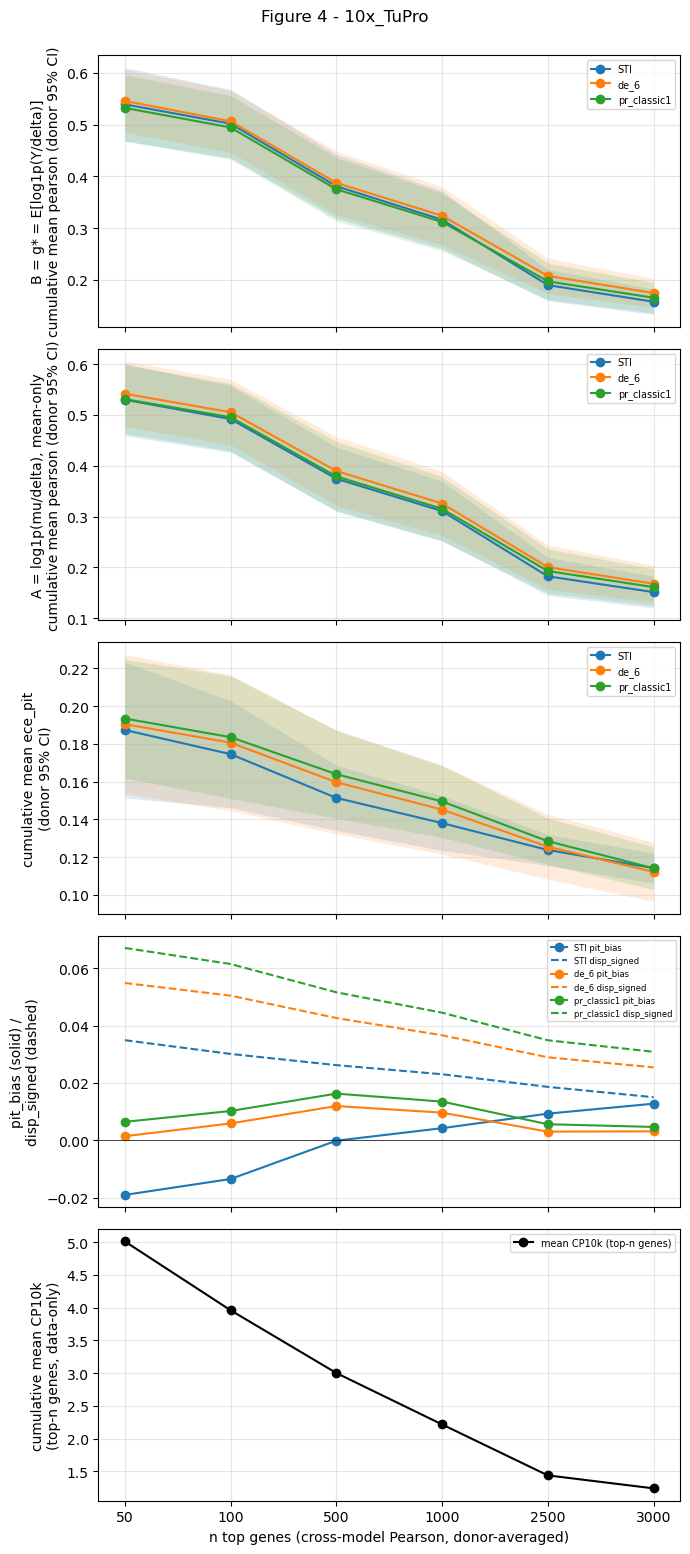


=== trajectories -- 10x_TuPro  [mean (ci_lo, ci_hi), donor 95% CI] ===
    n top genes = [50, 100, 500, 1000, 2500, 3000]

[pearson]
                                50                       100                      500                      1000                     2500                     3000
STI          0.5391 (0.4680, 0.6102)  0.5017 (0.4356, 0.5678)  0.3809 (0.3194, 0.4424)  0.3161 (0.2603, 0.3720)  0.1898 (0.1597, 0.2198)  0.1576 (0.1329, 0.1823)
de_6         0.5457 (0.4852, 0.6062)  0.5064 (0.4467, 0.5662)  0.3874 (0.3262, 0.4486)  0.3238 (0.2678, 0.3799)  0.2075 (0.1733, 0.2417)  0.1745 (0.1465, 0.2025)
pr_classic1  0.5323 (0.4682, 0.5963)  0.4944 (0.4331, 0.5557)  0.3751 (0.3139, 0.4363)  0.3118 (0.2564, 0.3672)  0.1970 (0.1615, 0.2326)  0.1653 (0.1360, 0.1947)

[pearson_logmean]
                                50                       100                      500                      1000                     2500                     3000
STI          0.5301 (0.4593, 0.6009) 

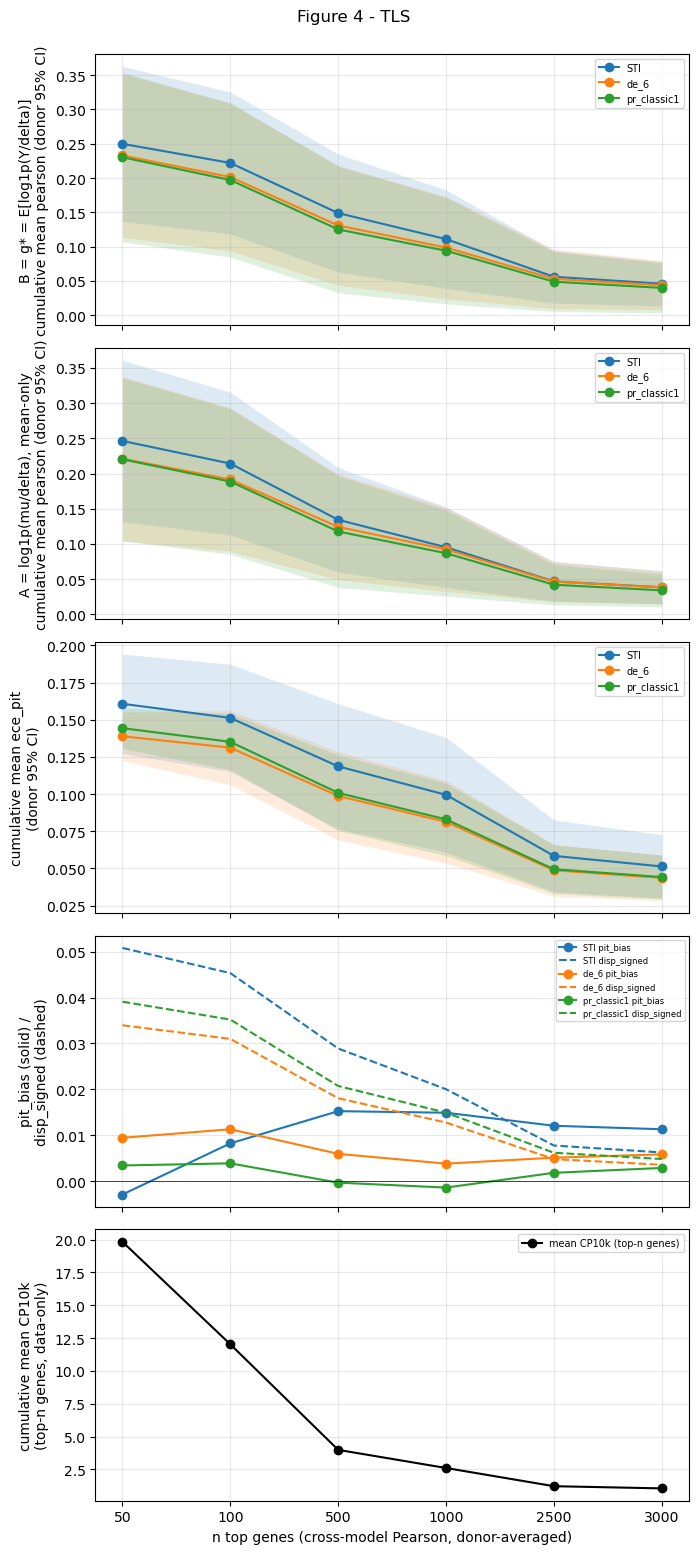


=== trajectories -- TLS  [mean (ci_lo, ci_hi), donor 95% CI] ===
    n top genes = [50, 100, 500, 1000, 2500, 3000]

[pearson]
                                50                       100                      500                      1000                     2500                     3000
STI          0.2499 (0.1370, 0.3628)  0.2220 (0.1185, 0.3254)  0.1489 (0.0630, 0.2348)  0.1110 (0.0392, 0.1827)  0.0561 (0.0178, 0.0945)  0.0460 (0.0137, 0.0783)
de_6         0.2329 (0.1133, 0.3525)  0.2014 (0.0939, 0.3090)  0.1309 (0.0436, 0.2181)  0.0986 (0.0240, 0.1732)  0.0531 (0.0099, 0.0964)  0.0438 (0.0077, 0.0799)
pr_classic1  0.2303 (0.1070, 0.3536)  0.1971 (0.0848, 0.3094)  0.1251 (0.0329, 0.2174)  0.0941 (0.0166, 0.1715)  0.0490 (0.0056, 0.0923)  0.0399 (0.0035, 0.0763)

[pearson_logmean]
                                50                       100                      500                      1000                     2500                     3000
STI          0.2463 (0.1317, 0.3610)  0.214

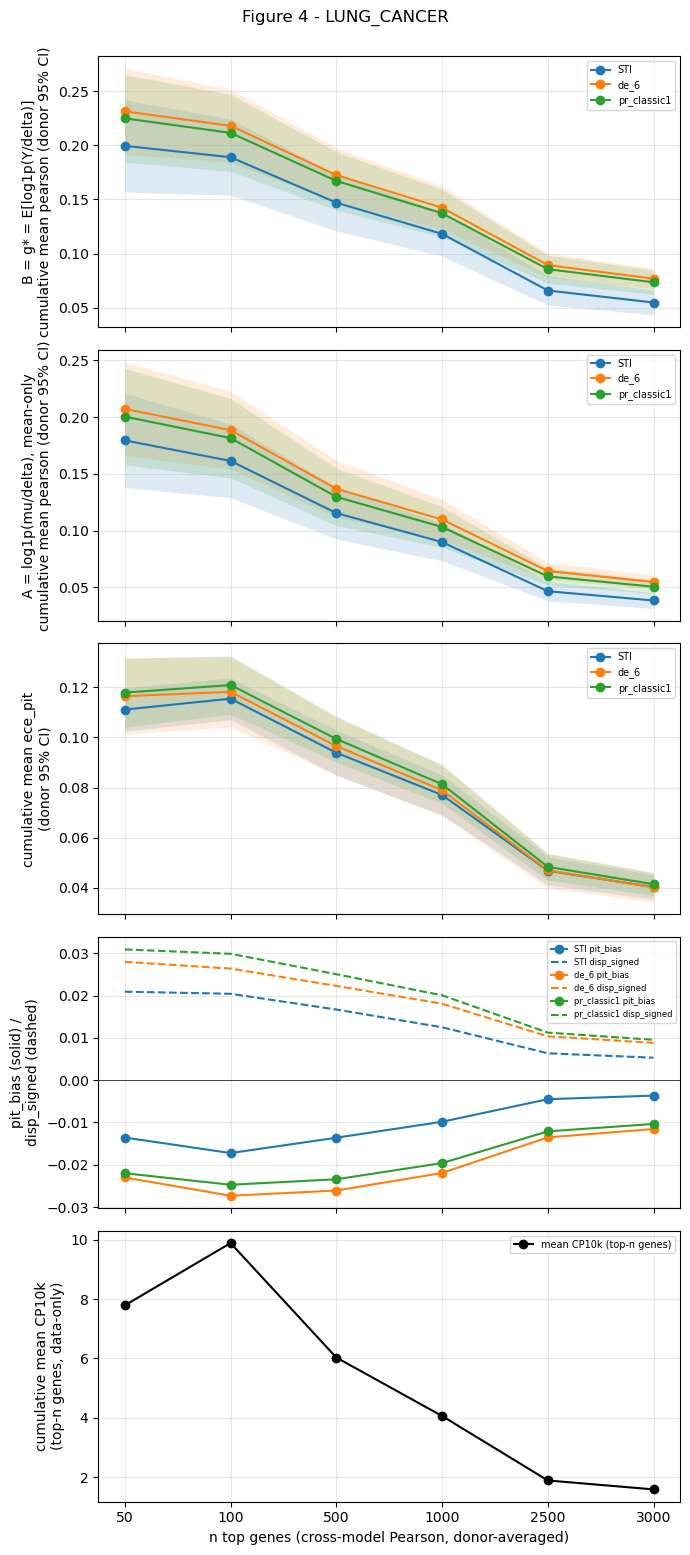


=== trajectories -- LUNG_CANCER  [mean (ci_lo, ci_hi), donor 95% CI] ===
    n top genes = [50, 100, 500, 1000, 2500, 3000]

[pearson]
                                50                       100                      500                      1000                     2500                     3000
STI          0.1994 (0.1568, 0.2420)  0.1890 (0.1538, 0.2241)  0.1470 (0.1209, 0.1731)  0.1181 (0.0976, 0.1387)  0.0658 (0.0524, 0.0793)  0.0548 (0.0434, 0.0661)
de_6         0.2313 (0.1918, 0.2709)  0.2180 (0.1842, 0.2518)  0.1725 (0.1476, 0.1974)  0.1423 (0.1225, 0.1621)  0.0893 (0.0782, 0.1004)  0.0767 (0.0673, 0.0861)
pr_classic1  0.2248 (0.1845, 0.2652)  0.2114 (0.1759, 0.2470)  0.1671 (0.1401, 0.1940)  0.1372 (0.1153, 0.1592)  0.0855 (0.0727, 0.0984)  0.0734 (0.0623, 0.0846)

[pearson_logmean]
                                50                       100                      500                      1000                     2500                     3000
STI          0.1794 (0.1380, 0.2209

In [23]:
def cumulative_donor_ci(mat, order, ns):
    mat_ordered = mat.reindex(order)
    rows = []
    for n in ns:
        per_donor = mat_ordered.iloc[:n].mean(axis=0, skipna=True)
        stats = donor_lopo_stats(per_donor.to_dict())
        rows.append(dict(n=n, mean=stats["mean"], ci_lo=stats["ci95_mean"][0], ci_hi=stats["ci95_mean"][1]))
    return pd.DataFrame(rows)

def cumulative_gene_property(series, order, ns):
    s_ordered = series.reindex(order)
    rows = [dict(n=n, mean=float(s_ordered.iloc[:n].mean(skipna=True)), ci_lo=np.nan, ci_hi=np.nan) for n in ns]
    return pd.DataFrame(rows)

def print_trajectories(traj, ns, title):
    """Print the plotted curves numerically under the figure: one table per metric, rows = model
    label, columns = n cutoff, cell = 'mean (ci_lo, ci_hi)' (donor 95% CI), or just 'mean' when
    there is no CI (the model-independent expression curve or a baseline curve)."""
    def _fmt(r):
        if np.isfinite(r["ci_lo"]) and np.isfinite(r["ci_hi"]):
            return f"{r['mean']:.4f} ({r['ci_lo']:.4f}, {r['ci_hi']:.4f})"
        return f"{r['mean']:.4f}"
    print(f"\n=== trajectories -- {title}  [mean (ci_lo, ci_hi), donor 95% CI] ===")
    print(f"    n top genes = {ns}")
    for metric, per_model in traj.items():
        if not per_model:
            continue
        tbl = pd.DataFrame({
            lbl: {int(r["n"]): _fmt(r) for _, r in cur.iterrows()}
            for lbl, cur in per_model.items()
        }).T.reindex(columns=ns)
        print(f"\n[{metric}]")
        print(tbl.to_string())

def figure4(group, title):
    shared_genes = None
    rank_pieces = []
    for s in group:
        mat_p = gene_donor_matrix(s["per_long"], "pearson")
        shared_genes = set(mat_p.index) if shared_genes is None else shared_genes & set(mat_p.index)
        rank_pieces.append(mat_p.mean(axis=1))
    shared_genes = sorted(shared_genes)
    order = pd.concat(rank_pieces, axis=1).loc[shared_genes].mean(axis=1).sort_values(ascending=False).index

    ns = sorted(set(n for n in [50, 100, 500, 1000, 2500, len(order)] if n <= len(order)))
    x = np.arange(len(ns))
    ds = group[0]["dataset"]
    expr_cp = EXPR_BY_DS[ds]["mean_cp10k"].reindex(shared_genes)

    # Each plotted curve's numeric trajectory, accumulated here to print under the figure.
    traj = {"pearson": {}, "pearson_logmean": {}, "ece_pit": {}, "pit_bias": {},
            "disp_signed": {}, "mean_cp10k_expr": {}}

    # Panels: B (g*) then A (mean-only) directly under it. BOTH use the SAME gene ordering
    # (`order`, ranked on B), so the two panels are comparable point-by-point and their vertical
    # difference at a given n IS the Jensen gap. See src/evaluation/count_metrics.py.
    fig, (axp, axa, axe, axb, axm) = plt.subplots(5, 1, figsize=(7, 15.5), sharex=True)
    for s in group:
        c = COLORS[s["label"]]
        mat_p = gene_donor_matrix(s["per_long"], "pearson").reindex(shared_genes)
        curve = cumulative_donor_ci(mat_p, order, ns)
        traj["pearson"][s["label"]] = curve
        axp.fill_between(x, curve["ci_lo"], curve["ci_hi"], color=c, alpha=0.15, linewidth=0)
        axp.plot(x, curve["mean"], "-o", color=c, label=s["label"])

        # A = log1p(mu/delta), mean-only. COUNT-ONLY column: a Gaussian arm simply has no
        # pearson_logmean, hence the guard (same pattern as the ece_pit guard below).
        if "pearson_logmean" in s["per_long"].columns:
            mat_a = gene_donor_matrix(s["per_long"], "pearson_logmean").reindex(shared_genes)
            curve_a = cumulative_donor_ci(mat_a, order, ns)
            traj["pearson_logmean"][s["label"]] = curve_a
            axa.fill_between(x, curve_a["ci_lo"], curve_a["ci_hi"], color=c, alpha=0.15, linewidth=0)
            axa.plot(x, curve_a["mean"], "-o", color=c, label=s["label"])

        if "ece_pit" in s["per_long"].columns:
            mat_e = gene_donor_matrix(s["per_long"], "ece_pit").reindex(shared_genes)
            curve_e = cumulative_donor_ci(mat_e, order, ns)
            traj["ece_pit"][s["label"]] = curve_e
            axe.fill_between(x, curve_e["ci_lo"], curve_e["ci_hi"], color=c, alpha=0.15, linewidth=0)
            axe.plot(x, curve_e["mean"], "-o", color=c, label=s["label"])
        if "pit_bias" in s["per_long"].columns:
            mat_pb = gene_donor_matrix(s["per_long"], "pit_bias").reindex(shared_genes)
            curve_pb = cumulative_donor_ci(mat_pb, order, ns)
            traj["pit_bias"][s["label"]] = curve_pb
            axb.plot(x, curve_pb["mean"], "-o", color=c, label=f"{s['label']} pit_bias")
        if "disp_signed" in s["per_long"].columns:
            mat_ds = gene_donor_matrix(s["per_long"], "disp_signed").reindex(shared_genes)
            curve_ds = cumulative_donor_ci(mat_ds, order, ns)
            traj["disp_signed"][s["label"]] = curve_ds
            axb.plot(x, curve_ds["mean"], "--", color=c, label=f"{s['label']} disp_signed")

    curve_m = cumulative_gene_property(expr_cp, order, ns)
    traj["mean_cp10k_expr"]["top-n genes (data-only)"] = curve_m
    axm.plot(x, curve_m["mean"], "-o", color="black", label="mean CP10k (top-n genes)")

    axp.set_ylabel("B = g* = E[log1p(Y/delta)]\ncumulative mean pearson (donor 95% CI)")
    axp.grid(alpha=0.3); axp.legend(fontsize=7)
    axa.set_ylabel("A = log1p(mu/delta), mean-only\ncumulative mean pearson (donor 95% CI)")
    axa.grid(alpha=0.3)
    if traj["pearson_logmean"]:
        axa.legend(fontsize=7)
    else:   # no count arm in this group -> A is undefined; say so instead of an empty panel
        axa.text(0.5, 0.5, "A is count-only -- no count model in this group",
                 ha="center", va="center", transform=axa.transAxes, fontsize=8, color="gray")
    axe.set_ylabel("cumulative mean ece_pit\n(donor 95% CI)"); axe.grid(alpha=0.3); axe.legend(fontsize=7)
    axb.axhline(0, color="black", linewidth=0.5)
    axb.set_ylabel("pit_bias (solid) /\ndisp_signed (dashed)"); axb.grid(alpha=0.3); axb.legend(fontsize=6)
    axm.set_ylabel("cumulative mean CP10k\n(top-n genes, data-only)"); axm.grid(alpha=0.3); axm.legend(fontsize=7)
    axm.set_xticks(x); axm.set_xticklabels([str(n) for n in ns])
    axm.set_xlabel("n top genes (cross-model Pearson, donor-averaged)")
    fig.suptitle(f"Figure 4 - {title}", y=1.0)
    plt.tight_layout(); plt.show()

    print_trajectories(traj, ns, title)

for ds, group in by_dataset.items():
    figure4(group, ds)


## 6. Per-gene Pearson vs mean expression and % zeros (scatter, one row per model)

One figure per dataset; grid `model x {CP10k expression (log x), % zeros}`. y = per-gene Pearson (mean over donors), x = a data-only property of the gene. Each title gives `Spearman(Pearson, x)` over genes.


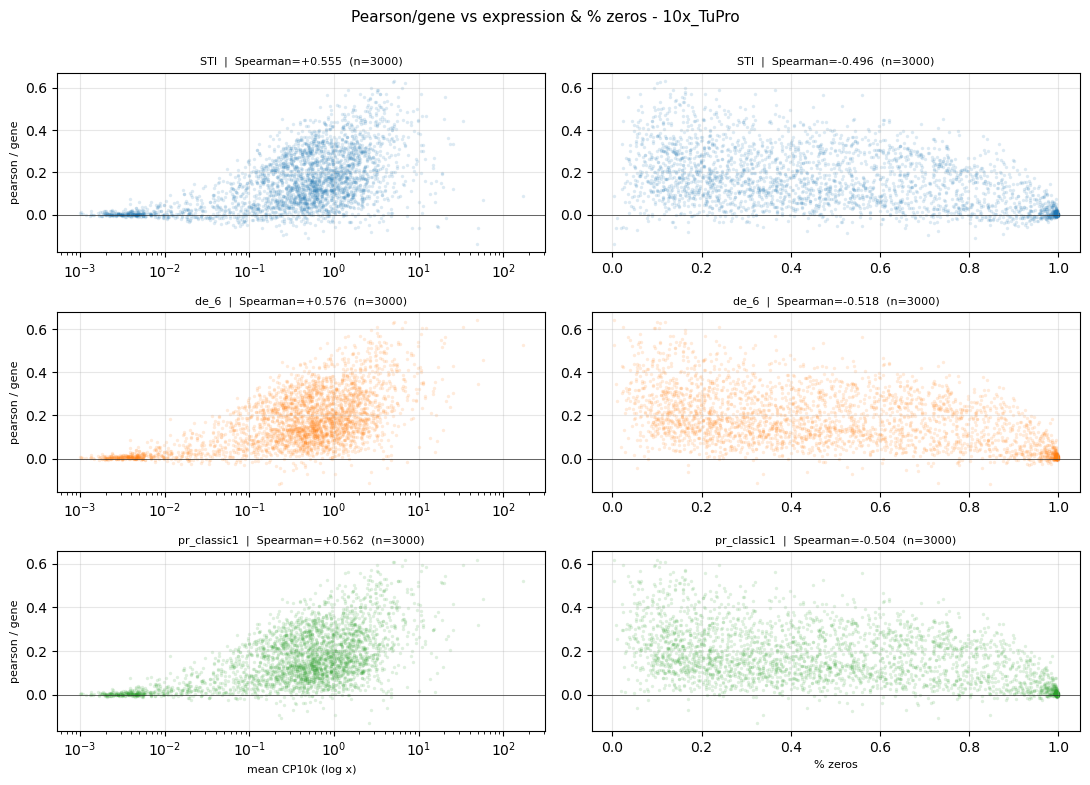

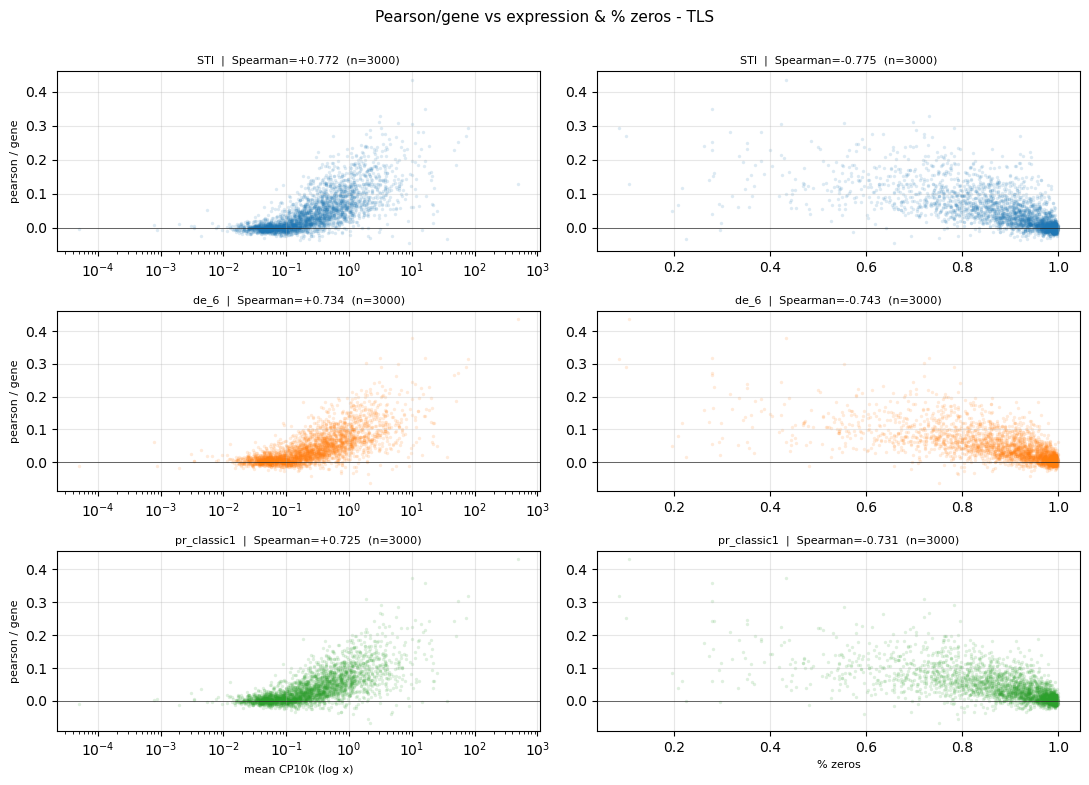

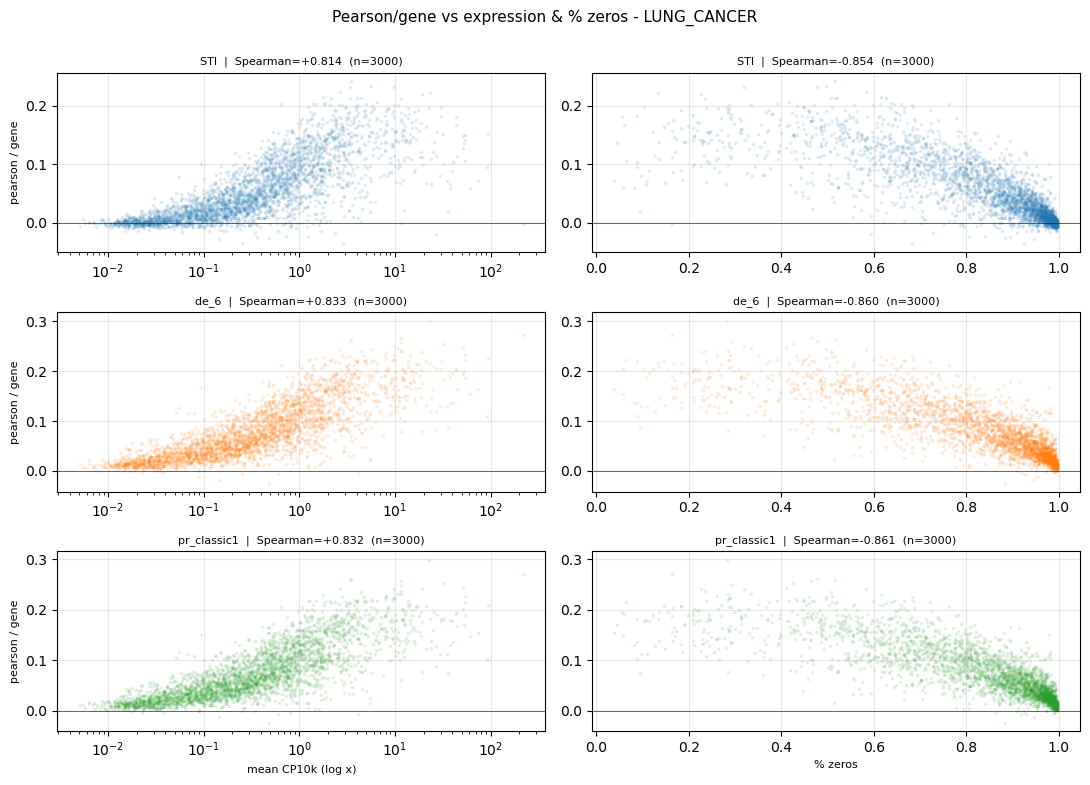

-- Spearman(per-gene pearson, x), the numbers behind the scatter titles above --
x                        mean_cp10k  pct_zeros
dataset     model                             
10x_TuPro   STI              0.5548    -0.4955
            de_6             0.5755    -0.5185
            pr_classic1      0.5617    -0.5042
LUNG_CANCER STI              0.8143    -0.8540
            de_6             0.8332    -0.8603
            pr_classic1      0.8317    -0.8609
TLS         STI              0.7723    -0.7748
            de_6             0.7340    -0.7434
            pr_classic1      0.7253    -0.7307


In [24]:
from scipy.stats import spearmanr

SCATTER_X = [("mean_cp10k", "mean CP10k (log x)", True), ("pct_zeros", "% zeros", False)]
scatter_rows = []   # printed table instead of reading it off the plot titles

for ds, group in by_dataset.items():
    expr = EXPR_BY_DS[ds]
    fig, axes = plt.subplots(len(group), 2, figsize=(11, 2.6 * len(group)), squeeze=False)
    for i, s in enumerate(group):
        per_gene = gene_donor_matrix(s["per_long"], "pearson").mean(axis=1)
        df = pd.DataFrame({"pearson": per_gene}).join(expr, how="inner")
        c = COLORS[s["label"]]
        for j, (xcol, xlabel, logx) in enumerate(SCATTER_X):
            ax = axes[i, j]
            xv, yv = df[xcol].to_numpy(), df["pearson"].to_numpy()
            ok = np.isfinite(xv) & np.isfinite(yv) & ((xv > 0) if logx else True)
            ax.scatter(xv[ok], yv[ok], s=6, alpha=0.15, color=c, linewidths=0)
            if logx:
                ax.set_xscale("log")
            rho = spearmanr(xv[ok], yv[ok]).correlation if ok.sum() > 2 else np.nan
            ax.set_title(f"{s['label']}  |  Spearman={rho:+.3f}  (n={int(ok.sum())})", fontsize=8)
            ax.axhline(0, color="black", linewidth=0.4); ax.grid(alpha=0.3)
            if i == len(group) - 1:
                ax.set_xlabel(xlabel, fontsize=8)
            if j == 0:
                ax.set_ylabel("pearson / gene", fontsize=8)
            scatter_rows.append(dict(dataset=ds, model=s["label"], x=xcol, spearman=rho, n=int(ok.sum())))
    fig.suptitle(f"Pearson/gene vs expression & % zeros - {ds}", y=1.0, fontsize=11)
    plt.tight_layout(); plt.show()

print("-- Spearman(per-gene pearson, x), the numbers behind the scatter titles above --")
scatter_df = pd.DataFrame(scatter_rows)
print(scatter_df.pivot_table(index=["dataset", "model"], columns="x", values="spearman").round(4).to_string())


## 7. Figure 5: calibration vs the marginal baseline (no H&E)

Baseline: distribution fitted directly on each gene's true expression, no image (`canal1_marginal_calibration_baseline_precompute.py`, model-independent, on the same common-depth target as the `_cp` models -- one constant per dataset, `depth_scale` = 2.5 on 10x_TuPro and 1.0 on TLS / LUNG_CANCER, never a per-spot size factor). The 2 NB models of this notebook (`STI_nb_cp`, `negativebinomial_hetero_noanchor_cp`) both share the `nb` family (`FAMILY_OF`, section 0) -> a single baseline curve per dataset. Overlaid on the same gene ranking as Figure 4: solid = model (H&E), dotted = marginal baseline.


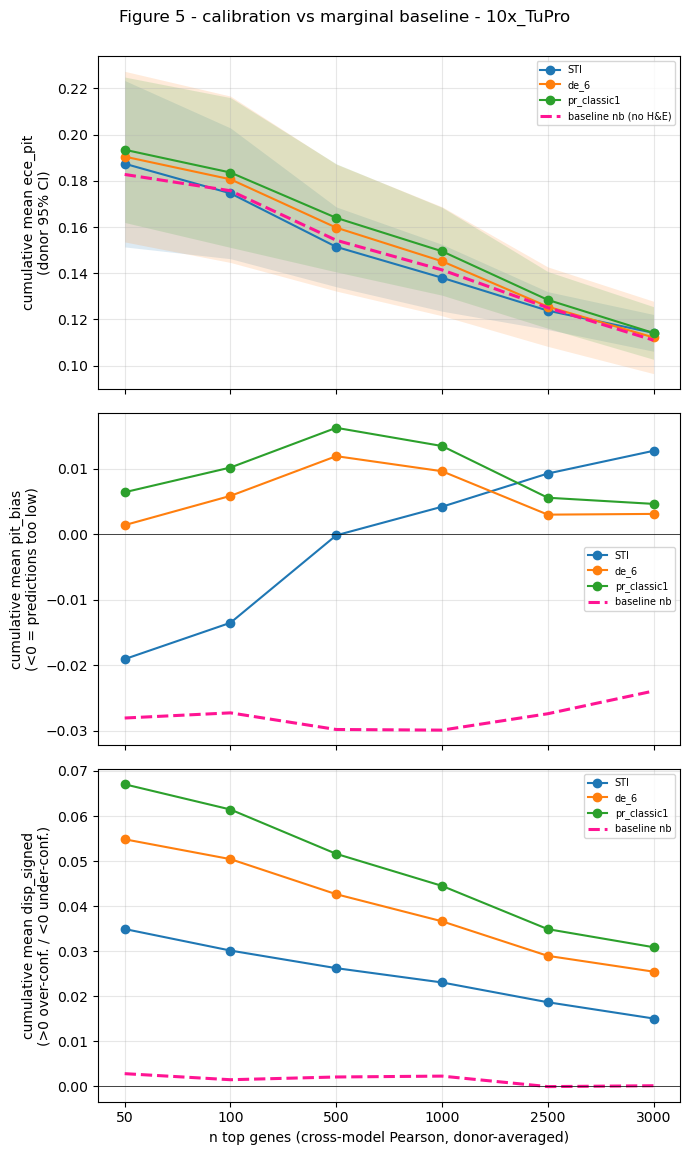


=== trajectories -- 10x_TuPro  [mean (ci_lo, ci_hi), donor 95% CI] ===
    n top genes = [50, 100, 500, 1000, 2500, 3000]

[ece_pit]
                                50                       100                      500                      1000                     2500                     3000
STI          0.1874 (0.1514, 0.2234)  0.1746 (0.1463, 0.2028)  0.1514 (0.1342, 0.1687)  0.1381 (0.1236, 0.1525)  0.1238 (0.1156, 0.1320)  0.1142 (0.1063, 0.1222)
de_6         0.1904 (0.1536, 0.2273)  0.1806 (0.1447, 0.2166)  0.1597 (0.1323, 0.1872)  0.1452 (0.1216, 0.1688)  0.1256 (0.1084, 0.1427)  0.1122 (0.0966, 0.1279)
pr_classic1  0.1934 (0.1620, 0.2249)  0.1836 (0.1512, 0.2159)  0.1640 (0.1406, 0.1873)  0.1495 (0.1305, 0.1685)  0.1285 (0.1162, 0.1407)  0.1142 (0.1028, 0.1255)
baseline:nb  0.1827 (0.1433, 0.2222)  0.1757 (0.1446, 0.2068)  0.1543 (0.1340, 0.1745)  0.1415 (0.1231, 0.1598)  0.1251 (0.1145, 0.1357)  0.1110 (0.1015, 0.1206)

[pit_bias]
                                  50        

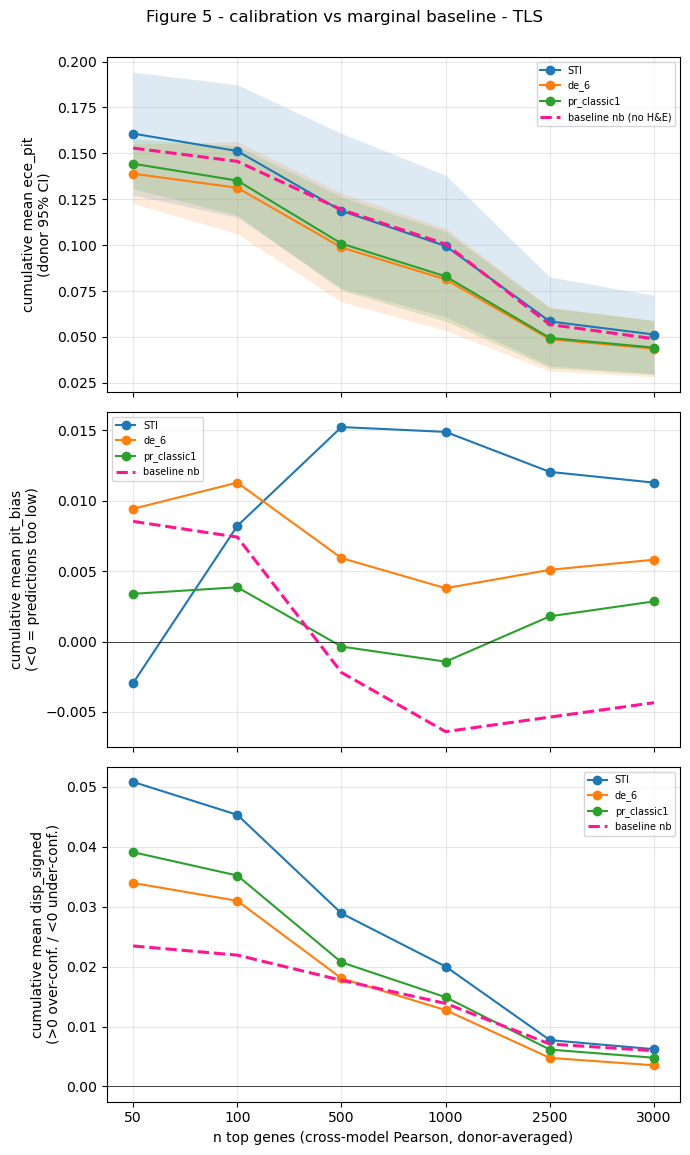


=== trajectories -- TLS  [mean (ci_lo, ci_hi), donor 95% CI] ===
    n top genes = [50, 100, 500, 1000, 2500, 3000]

[ece_pit]
                                50                       100                      500                      1000                     2500                     3000
STI          0.1608 (0.1273, 0.1942)  0.1513 (0.1151, 0.1874)  0.1187 (0.0765, 0.1608)  0.0995 (0.0610, 0.1381)  0.0585 (0.0343, 0.0827)  0.0513 (0.0300, 0.0727)
de_6         0.1389 (0.1227, 0.1552)  0.1313 (0.1062, 0.1563)  0.0988 (0.0691, 0.1284)  0.0814 (0.0536, 0.1091)  0.0488 (0.0314, 0.0662)  0.0437 (0.0284, 0.0590)
pr_classic1  0.1443 (0.1307, 0.1580)  0.1352 (0.1163, 0.1540)  0.1008 (0.0755, 0.1262)  0.0830 (0.0586, 0.1074)  0.0495 (0.0331, 0.0658)  0.0442 (0.0294, 0.0590)
baseline:nb  0.1529 (0.1437, 0.1620)  0.1456 (0.1245, 0.1668)  0.1193 (0.0856, 0.1531)  0.1006 (0.0668, 0.1343)  0.0568 (0.0360, 0.0776)  0.0490 (0.0312, 0.0669)

[pit_bias]
                                  50              

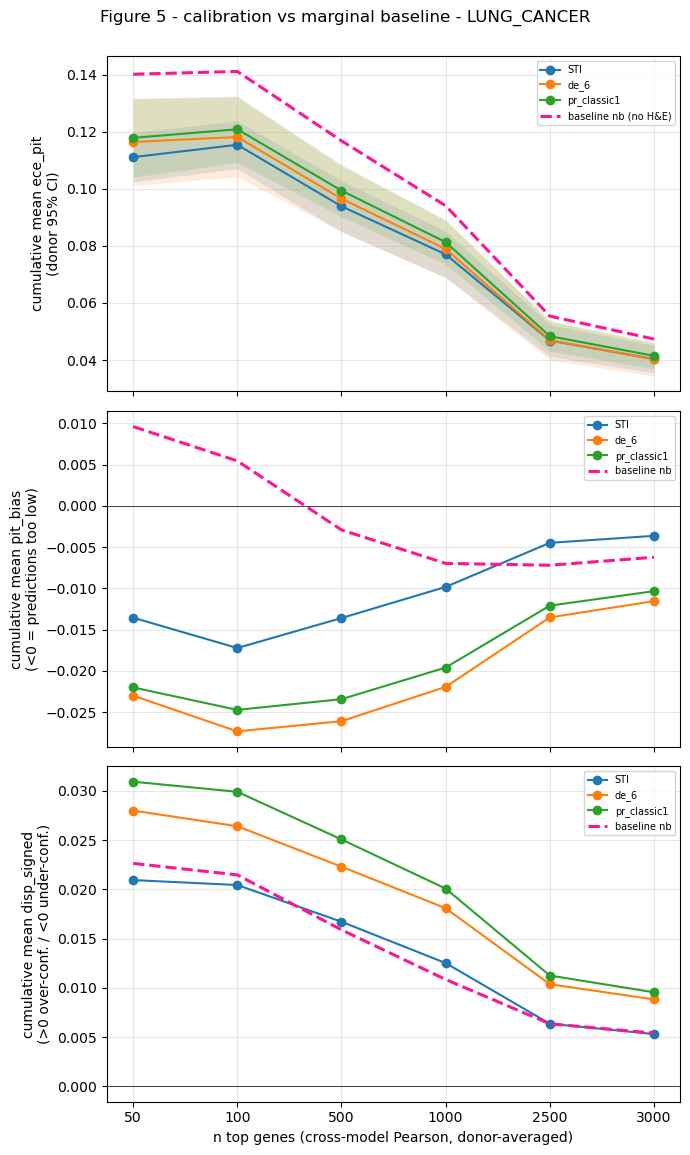


=== trajectories -- LUNG_CANCER  [mean (ci_lo, ci_hi), donor 95% CI] ===
    n top genes = [50, 100, 500, 1000, 2500, 3000]

[ece_pit]
                                50                       100                      500                      1000                     2500                     3000
STI          0.1111 (0.1024, 0.1197)  0.1154 (0.1071, 0.1238)  0.0939 (0.0849, 0.1029)  0.0770 (0.0690, 0.0851)  0.0469 (0.0413, 0.0524)  0.0403 (0.0355, 0.0452)
de_6         0.1164 (0.1012, 0.1316)  0.1182 (0.1042, 0.1322)  0.0965 (0.0851, 0.1080)  0.0789 (0.0689, 0.0890)  0.0470 (0.0401, 0.0539)  0.0403 (0.0343, 0.0462)
pr_classic1  0.1179 (0.1041, 0.1316)  0.1209 (0.1092, 0.1325)  0.0994 (0.0902, 0.1085)  0.0813 (0.0736, 0.0891)  0.0484 (0.0431, 0.0536)  0.0415 (0.0370, 0.0460)
baseline:nb  0.1402 (0.1197, 0.1606)  0.1411 (0.1214, 0.1609)  0.1168 (0.0968, 0.1368)  0.0941 (0.0788, 0.1094)  0.0554 (0.0465, 0.0643)  0.0474 (0.0398, 0.0550)

[pit_bias]
                                  50      

In [25]:
METRICS_F5 = ["ece_pit", "pit_bias", "disp_signed"]

def _cum(src, metric, order, ns, shared_genes, is_pivot=False):
    mat = (src if is_pivot else gene_donor_matrix(src, metric)).reindex(shared_genes)
    return cumulative_donor_ci(mat, order, ns)

def figure5(group, title):
    shared_genes = None
    rank_pieces = []
    for s in group:
        mat_p = gene_donor_matrix(s["per_long"], "pearson")
        shared_genes = set(mat_p.index) if shared_genes is None else shared_genes & set(mat_p.index)
        rank_pieces.append(mat_p.mean(axis=1))
    shared_genes = sorted(shared_genes)
    order = pd.concat(rank_pieces, axis=1).loc[shared_genes].mean(axis=1).sort_values(ascending=False).index
    ns = sorted(set(n for n in [50, 100, 500, 1000, 2500, len(order)] if n <= len(order)))
    x = np.arange(len(ns))

    ds = group[0]["dataset"]
    bl = pd.read_parquet(BASELINE_DIR / f"{ds}.parquet")
    traj_fams = set()
    traj = {m: {} for m in METRICS_F5}   # numeric trajectory of every plotted curve, printed below

    fig, axs = plt.subplots(3, 1, figsize=(7, 11.5), sharex=True)
    for s in group:
        if "ece_pit" not in s["per_long"].columns:
            continue
        c = COLORS[s["label"]]
        traj_fams.add(FAMILY_OF.get(s["model_type"]))
        for ax, m in zip(axs, METRICS_F5):
            cur = _cum(s["per_long"], m, order, ns, shared_genes)
            traj[m][s["label"]] = cur
            if m == "ece_pit":
                ax.fill_between(x, cur["ci_lo"], cur["ci_hi"], color=c, alpha=0.15, linewidth=0)
            ax.plot(x, cur["mean"], "-o", color=c, label=s["label"])

    for fam in sorted(traj_fams):
        if fam is None or fam not in BASELINE_COLOR:
            continue
        cc = BASELINE_COLOR[fam]
        sub = bl[bl["family"] == fam]
        for ax, m in zip(axs, METRICS_F5):
            piv = sub.pivot_table(index="gene", columns="test_donor", values=m)
            cur = _cum(piv, None, order, ns, shared_genes, is_pivot=True)
            traj[m][f"baseline:{fam}"] = cur
            ax.plot(x, cur["mean"], "--", color=cc, linewidth=2.2,
                    label=f"baseline {fam}" + (" (no H&E)" if m == "ece_pit" else ""))

    axs[0].set_ylabel("cumulative mean ece_pit\n(donor 95% CI)")
    axs[1].axhline(0, color="black", linewidth=0.5)
    axs[1].set_ylabel("cumulative mean pit_bias\n(<0 = predictions too low)")
    axs[2].axhline(0, color="black", linewidth=0.5)
    axs[2].set_ylabel("cumulative mean disp_signed\n(>0 over-conf. / <0 under-conf.)")
    for ax in axs:
        ax.grid(alpha=0.3); ax.legend(fontsize=7)
    axs[2].set_xticks(x); axs[2].set_xticklabels([str(n) for n in ns])
    axs[2].set_xlabel("n top genes (cross-model Pearson, donor-averaged)")
    fig.suptitle(f"Figure 5 - calibration vs marginal baseline - {title}", y=1.0)
    plt.tight_layout(); plt.show()

    print_trajectories(traj, ns, title)

for ds, group in by_dataset.items():
    figure5(group, ds)


## Read-off

- **Section 2 (headline)**: does `STI` (STimage) beat our NB? Does `de_6` (5-seed ensemble) beat `pr_classic1` (single run), i.e. is the gain worth the 5x cost?
- **Section 2, table B - A**: the Jensen gap. Positive => routing through the full predictive (`mu` AND `alpha`) really helps; close to 0 => the mean alone is enough and the dispersion adds nothing to mean performance.
- **Section 3 vs 2**: a large gap between the median and the donor-weighted mean signals a strongly skewed per-gene distribution.
- **Figure 4, panels 1 vs 2 (B vs A)**: is the model ranking the SAME under both estimators? If it changes, the comparison depends on the estimator chosen and must be reported under both (which is why both are reported).
- **Figure 4 (CI)**: does the band tighten as more genes are included? Is the ranking already stable at the first 50 genes?
- **Figure 5 (section 8)**: do the models calibrate better than their family's marginal baseline (solid curve below the dashed one), or does their calibration come mostly from the NB structure rather than from histology (curves on top of each other)?
